<a href="https://colab.research.google.com/github/nirmit234/PROJECTS/blob/main/IFT6758_NHL_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import sys
print("Python version:", sys.version)

import os
print("Working directory:", os.getcwd())

Python version: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
Working directory: /content


In [ ]:
%pip install -q pandas numpy requests matplotlib seaborn plotly ipywidgets tqdm

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving ift6758_nhl_project_starter.zip to ift6758_nhl_project_starter.zip


In [ ]:
import zipfile
import os

zip_name = next(
    name for name in uploaded
    if name.lower().endswith(".zip")
)

with zipfile.ZipFile(zip_name, "r") as z:
    z.extractall("/content/ift6758_project")

print(os.listdir("/content/ift6758_project"))

['ift6758_nhl_project']


In [ ]:
from pathlib import Path

matches = list(Path("/content/ift6758_project").rglob("requirements.txt"))

for path in matches:
    print(path.parent)


/content/ift6758_project/ift6758_nhl_project


In [ ]:
from pathlib import Path
import os

PROJECT = matches[0].parent
os.chdir(PROJECT)

print("Project directory:", PROJECT)
print("Files:", os.listdir("."))

Project directory: /content/ift6758_project/ift6758_nhl_project
Files: ['blog', 'requirements.txt', 'data', 'notebooks', 'docs', 'outputs', 'README.md', 'src', '.gitignore']


In [ ]:
%pip install -r requirements.txt

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 44.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.2/17.2 MB 76.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 947.5/947.5 kB 31.7 MB/s  0:00:00
  Attempting uninstall: widgetsnbextension
    Found existing installation: widgetsnbextension 3.6.10
    Uninstalling widgetsnbextension-3.6.10:
      Successfully uninstalled widgetsnbextension-3.6.10
  Attempting uninstall: ipywidgets
    Found existing installation: ipywidgets 7.7.1
    Uninstalling ipywidgets-7.7.1:
      Successfully uninstalled ipywidgets-7.7.1
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11/11 [jupyter]


In [ ]:
from pathlib import Path

print("Downloader exists:", Path("src/acquire.py").exists())

Downloader exists: True


In [ ]:
!python -m src.acquire --game-id 2023021190

Cached/downloaded: 2023021190
Top-level keys: ['id', 'season', 'gameType', 'limitedScoring', 'gameDate', 'venue', 'venueLocation', 'startTimeUTC', 'easternUTCOffset', 'venueUTCOffset', 'tvBroadcasts', 'gameState', 'gameScheduleState', 'periodDescriptor', 'awayTeam', 'homeTeam', 'shootoutInUse', 'otInUse', 'clock', 'displayPeriod', 'maxPeriods', 'gameOutcome', 'plays', 'rosterSpots', 'regPeriods', 'summary']
Event/play keys: ['displayPeriod', 'plays']


In [ ]:
from pathlib import Path

json_files = list(Path(".").rglob("2023021190.json"))

if json_files:
    for path in json_files:
        print(path)
else:
    print("JSON file not found. Check the downloader output.")

data/raw/2023/2023021190.json


In [ ]:
import json

json_path = json_files[0]

with open(json_path, "r", encoding="utf-8") as f:
    game = json.load(f)

print("Top-level type:", type(game).__name__)

if isinstance(game, dict):
    print("\nTop-level keys:")
    for key, value in game.items():
        if isinstance(value, (dict, list)):
            print(f"{key}: {type(value).__name__}, length={len(value)}")
        else:
            print(f"{key}: {value}")

print("\nSample of actual JSON:")
print(json.dumps(game, indent=2)[:6000])

Top-level type: dict

Top-level keys:
id: 2023021190
season: 20232024
gameType: 2
limitedScoring: False
gameDate: 2024-04-02
venue: dict, length=1
venueLocation: dict, length=2
startTimeUTC: 2024-04-02T23:00:00Z
easternUTCOffset: -04:00
venueUTCOffset: -04:00
tvBroadcasts: list, length=3
gameState: OFF
gameScheduleState: OK
periodDescriptor: dict, length=3
awayTeam: dict, length=9
homeTeam: dict, length=9
shootoutInUse: True
otInUse: True
clock: dict, length=4
displayPeriod: 1
maxPeriods: 5
gameOutcome: dict, length=1
plays: list, length=345
rosterSpots: list, length=40
regPeriods: 3
summary: dict, length=0

Sample of actual JSON:
{
  "id": 2023021190,
  "season": 20232024,
  "gameType": 2,
  "limitedScoring": false,
  "gameDate": "2024-04-02",
  "venue": {
    "default": "Centre Bell"
  },
  "venueLocation": {
    "default": "Montreal",
    "fr": "Montr\u00e9al"
  },
  "startTimeUTC": "2024-04-02T23:00:00Z",
  "easternUTCOffset": "-04:00",
  "venueUTCOffset": "-04:00",
  "tvBroadcasts

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
SHOT_TYPES = {"SHOT", "GOAL"}
events = game.get("plays", game.get("events", []))

from collections import Counter

event_types = Counter(
    str(event.get("typeDescKey", event.get("type", "unknown")))
    for event in events
)

event_types.most_common(30)

[('shot-on-goal', 70),
 ('faceoff', 66),
 ('stoppage', 43),
 ('hit', 37),
 ('blocked-shot', 36),
 ('missed-shot', 32),
 ('penalty', 21),
 ('giveaway', 13),
 ('delayed-penalty', 8),
 ('goal', 8),
 ('takeaway', 4),
 ('period-start', 3),
 ('period-end', 3),
 ('game-end', 1)]

In [ ]:
tidy_path = PROJECT / "src" / "tidy.py"
source = tidy_path.read_text(encoding="utf-8")

source = source.replace(
    'SHOT_TYPES = {"SHOT", "GOAL"}',
    'SHOT_TYPES = {"SHOT", "SHOT_ON_GOAL", "GOAL"}'
)

tidy_path.write_text(source, encoding="utf-8")
print("Updated shot event types.")

Updated shot event types.


In [ ]:
from src.tidy import parse_game
import pandas as pd

rows = parse_game(
    game,
    game_id="2023021190",
    season_start_year=2023,
    game_type=2
)

test_df = pd.DataFrame(rows)

print("Rows extracted:", len(test_df))
display(test_df.head())
print(test_df.dtypes)

Rows extracted: 78


,season,season_start_year,game_type,game_id,event_id,event_type,is_goal,period,period_type,time_in_period,...,shooter_id,shooter_name,goalie_id,goalie_name,shot_type,empty_net,strength_label,strength,attacking_skaters,defending_skaters
0,2023-24,2023,2,2023021190,108,shot,False,1,REG,00:28,...,8475765,{'default': 'Vladimir'} {'default': 'Tarasenko'},8478470,{'default': 'Samuel'} {'default': 'Montembeault'},wrist,None,even,5-on-5,5,5
1,2023-24,2023,2,2023021190,120,shot,False,1,REG,01:54,...,8480185,{'default': 'Eetu'} {'default': 'Luostarinen'},8478470,{'default': 'Samuel'} {'default': 'Montembeault'},tip-in,None,power_play,5-on-4,5,4
2,2023-24,2023,2,2023021190,154,shot,False,1,REG,04:09,...,8482964,{'default': 'Arber'} {'default': 'Xhekaj'},8476932,{'default': 'Anthony'} {'default': 'Stolarz'},wrist,None,even,5-on-5,5,5
3,2023-24,2023,2,2023021190,201,shot,False,1,REG,04:54,...,8482087,{'default': 'Kaiden'} {'default': 'Guhle'},8476932,{'default': 'Anthony'} {'default': 'Stolarz'},snap,None,even,5-on-5,5,5
4,2023-24,2023,2,2023021190,205,shot,False,1,REG,05:16,...,8478859,{'default': 'Niko'} {'default': 'Mikkola'},8478470,{'default': 'Samuel'} {'default': 'Montembeault'},wrist,None,even,5-on-5,5,5


season               object
season_start_year     int64
game_type             int64
game_id              object
event_id              int64
event_type           object
is_goal                bool
period                int64
period_type          object
time_in_period       object
situation_code       object
team_id               int64
home_team_id          int64
away_team_id          int64
x                     int64
y                     int64
shooter_id            int64
shooter_name         object
goalie_id             int64
goalie_name          object
shot_type            object
empty_net            object
strength_label       object
strength             object
attacking_skaters     int64
defending_skaters     int64
dtype: object


In [ ]:
from src.acquire import download_season

summary = download_season(
    season_start_year=2016,
    max_regular_id=1400,
    max_playoff_id=250,
    pause_seconds=0.25
)

print(summary)

2016-2017: 100 cached games
2016-2017: 200 cached games
2016-2017: 300 cached games
2016-2017: 400 cached games
2016-2017: 500 cached games
2016-2017: 600 cached games
2016-2017: 700 cached games
2016-2017: 800 cached games
2016-2017: 900 cached games
2016-2017: 1000 cached games
2016-2017: 1100 cached games
2016-2017: 1200 cached games
{'season_start_year': 2016, 'found': 1298, 'missing': 352, 'errors': []}


In [ ]:
from src.tidy import build_dataframe

df = build_dataframe()

print("Rows:", len(df))
print("Columns:", df.columns.tolist())
display(df.head())

Rows: 78
Columns: ['season', 'season_start_year', 'game_type', 'game_id', 'event_id', 'event_type', 'is_goal', 'period', 'period_type', 'time_in_period', 'situation_code', 'team_id', 'home_team_id', 'away_team_id', 'x', 'y', 'shooter_id', 'shooter_name', 'goalie_id', 'goalie_name', 'shot_type', 'empty_net', 'strength_label', 'strength', 'attacking_skaters', 'defending_skaters']


,season,season_start_year,game_type,game_id,event_id,event_type,is_goal,period,period_type,time_in_period,...,shooter_id,shooter_name,goalie_id,goalie_name,shot_type,empty_net,strength_label,strength,attacking_skaters,defending_skaters
0,2023-24,2023,2,2023021190,108,shot,False,1,REG,00:28,...,8475765,{'default': 'Vladimir'} {'default': 'Tarasenko'},8478470,{'default': 'Samuel'} {'default': 'Montembeault'},wrist,None,even,5-on-5,5,5
1,2023-24,2023,2,2023021190,120,shot,False,1,REG,01:54,...,8480185,{'default': 'Eetu'} {'default': 'Luostarinen'},8478470,{'default': 'Samuel'} {'default': 'Montembeault'},tip-in,None,power_play,5-on-4,5,4
2,2023-24,2023,2,2023021190,154,shot,False,1,REG,04:09,...,8482964,{'default': 'Arber'} {'default': 'Xhekaj'},8476932,{'default': 'Anthony'} {'default': 'Stolarz'},wrist,None,even,5-on-5,5,5
3,2023-24,2023,2,2023021190,201,shot,False,1,REG,04:54,...,8482087,{'default': 'Kaiden'} {'default': 'Guhle'},8476932,{'default': 'Anthony'} {'default': 'Stolarz'},snap,None,even,5-on-5,5,5
4,2023-24,2023,2,2023021190,205,shot,False,1,REG,05:16,...,8478859,{'default': 'Niko'} {'default': 'Mikkola'},8478470,{'default': 'Samuel'} {'default': 'Montembeault'},wrist,None,even,5-on-5,5,5


In [ ]:
processed_dir = PROJECT / "data" / "processed"
processed_dir.mkdir(parents=True, exist_ok=True)

parquet_path = processed_dir / "shots_goals.parquet"
df.to_parquet(parquet_path, index=False)

print("Saved:", parquet_path)

Saved: /content/ift6758_project/ift6758_nhl_project/data/processed/shots_goals.parquet


In [ ]:
print("Empty dataset:", df.empty)
print("Duplicate game/event pairs:",
      df.duplicated(["game_id", "event_id"]).sum())

print("\nMissing values:")
display(df.isna().mean().sort_values(ascending=False).to_frame("missing_fraction"))

print("\nEvent types:")
display(df["event_type"].value_counts(dropna=False))

Empty dataset: False
Duplicate game/event pairs: 0

Missing values:


,missing_fraction
empty_net,1.0
season,0.0
game_type,0.0
game_id,0.0
event_id,0.0
event_type,0.0
is_goal,0.0
period,0.0
period_type,0.0
season_start_year,0.0



Event types:


,count
event_type,
shot,70
goal,8


In [ ]:
shot_summary = (
    df.groupby("shot_type", dropna=False)
      .agg(
          shots=("event_id", "count"),
          goals=("is_goal", "sum")
      )
      .reset_index()
)

shot_summary["goal_percentage"] = (
    100 * shot_summary["goals"] / shot_summary["shots"]
)

display(shot_summary.sort_values("shots", ascending=False))

,shot_type,shots,goals,goal_percentage
2,snap,35,4,11.428571
5,wrist,19,1,5.263158
3,tip-in,9,1,11.111111
0,backhand,7,1,14.285714
1,slap,7,0,0.000000
4,wrap-around,1,1,100.000000


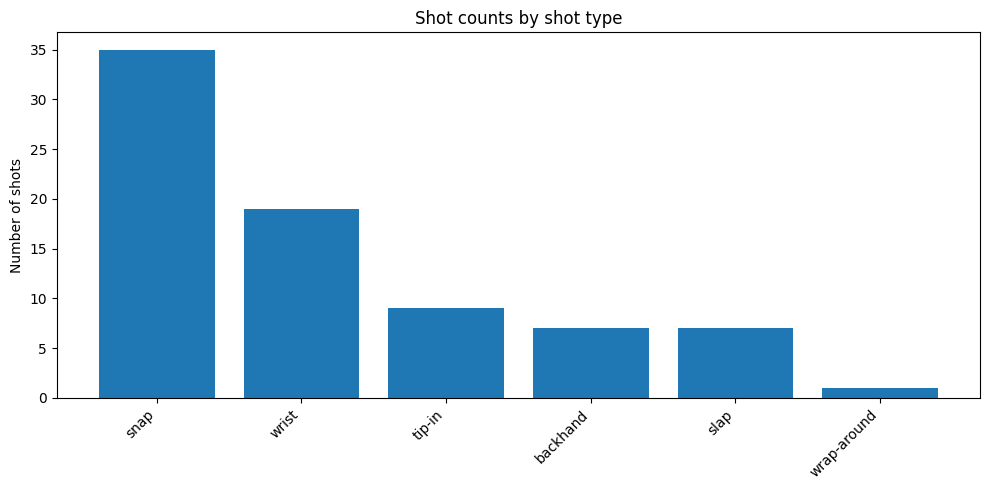

In [ ]:
import matplotlib.pyplot as plt

plot_df = shot_summary.sort_values("shots", ascending=False)

plt.figure(figsize=(10, 5))
plt.bar(plot_df["shot_type"].astype(str), plot_df["shots"])
plt.xticks(rotation=45, ha="right")
plt.ylabel("Number of shots")
plt.title("Shot counts by shot type")
plt.tight_layout()
plt.show()

In [ ]:
from pathlib import Path

print("Current directory:", Path.cwd())
print("Starter file exists:", Path("src/interactive_debug.py").exists())

if Path("src/interactive_debug.py").exists():
    print(Path("src/interactive_debug.py").read_text()[:12000])

print("\nParsed DataFrame columns:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

Current directory: /content/ift6758_project/ift6758_nhl_project
Starter file exists: True
"""Jupyter event browser. Run in a notebook after acquisition."""
from pathlib import Path
import json
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display, clear_output

RAW_DIR = Path("data/raw")

def list_games(season_start_year: int, game_type: int):
    return sorted((RAW_DIR / str(season_start_year)).glob(f"{season_start_year}{game_type:02d}*.json"))

def _events(payload):
    for key in ("plays", "events", "playByPlay"):
        if isinstance(payload.get(key), list):
            return payload[key]
    return []

def make_event_browser(season_start_year=2017, game_type=2):
    """Return/display controls to browse cached game events and coordinates."""
    games = list_games(season_start_year, game_type)
    if not games:
        print("No cached games for this season/type. Run acquisition first.")
        return
    game_dropdown = widgets.Dropdow

,season,season_start_year,game_type,game_id,event_id,event_type,is_goal,period,period_type,time_in_period,...,shooter_id,shooter_name,goalie_id,goalie_name,shot_type,empty_net,strength_label,strength,attacking_skaters,defending_skaters
0,2023-24,2023,2,2023021190,108,shot,False,1,REG,00:28,...,8475765,{'default': 'Vladimir'} {'default': 'Tarasenko'},8478470,{'default': 'Samuel'} {'default': 'Montembeault'},wrist,None,even,5-on-5,5,5
1,2023-24,2023,2,2023021190,120,shot,False,1,REG,01:54,...,8480185,{'default': 'Eetu'} {'default': 'Luostarinen'},8478470,{'default': 'Samuel'} {'default': 'Montembeault'},tip-in,None,power_play,5-on-4,5,4
2,2023-24,2023,2,2023021190,154,shot,False,1,REG,04:09,...,8482964,{'default': 'Arber'} {'default': 'Xhekaj'},8476932,{'default': 'Anthony'} {'default': 'Stolarz'},wrist,None,even,5-on-5,5,5
3,2023-24,2023,2,2023021190,201,shot,False,1,REG,04:54,...,8482087,{'default': 'Kaiden'} {'default': 'Guhle'},8476932,{'default': 'Anthony'} {'default': 'Stolarz'},snap,None,even,5-on-5,5,5
4,2023-24,2023,2,2023021190,205,shot,False,1,REG,05:16,...,8478859,{'default': 'Niko'} {'default': 'Mikkola'},8478470,{'default': 'Samuel'} {'default': 'Montembeault'},wrist,None,even,5-on-5,5,5


In [ ]:
import json
import re
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import ipywidgets as widgets

from IPython.display import display, clear_output

# 1. Locate raw NHL game files
RAW_DIR = Path("data/raw")
raw_games = {}

for path in RAW_DIR.rglob("*.json"):
    match = re.search(r"\d{10}", path.stem)

    if not match:
        continue

    game_id = match.group(0)

    try:
        with open(path, "r", encoding="utf-8") as f:
            payload = json.load(f)

        if isinstance(payload, dict) and isinstance(
            payload.get("plays"), list
        ):
            raw_games[game_id] = payload

    except (json.JSONDecodeError, OSError) as e:
        print(f"Could not read {path}: {e}")

print("Raw games loaded:", len(raw_games))

if not raw_games:
    raise ValueError(
        "No raw games found. Check RAW_DIR and the JSON filenames."
    )

# 2. Create interactive controls
game_dropdown = widgets.Dropdown(
    options=sorted(raw_games.keys()),
    description="Game:",
    layout=widgets.Layout(width="450px")
)

event_slider = widgets.IntSlider(
    value=0,
    min=0,
    max=0,
    step=1,
    description="Event:",
    continuous_update=False,
    layout=widgets.Layout(width="450px")
)

event_output = widgets.Output()


def update_event_range(change=None):
    game_id = game_dropdown.value
    plays = raw_games[game_id]["plays"]

    event_slider.max = max(0, len(plays) - 1)
    event_slider.value = 0


def get_parsed_row(game_id, event):
    """Find a matching row in df, when the columns are available."""
    if not isinstance(df, pd.DataFrame):
        return None

    columns = set(df.columns)

    if "game_id" not in columns:
        return None

    # Match game ID even if one version is an integer.
    game_mask = df["game_id"].astype(str).str.replace(
        r"\.0$", "", regex=True
    ) == str(game_id)

    # Raw NHL event identifier.
    raw_event_id = event.get("eventId")

    if raw_event_id is None or "event_id" not in columns:
        return df.loc[game_mask].head(0)

    event_mask = (
        df["event_id"].astype(str)
        == str(raw_event_id)
    )

    return df.loc[game_mask & event_mask]


def draw_rink(ax):
    """Draw a simple rink outline for coordinate inspection."""
    from matplotlib.patches import Rectangle, Circle

    ax.add_patch(
        Rectangle((-100, -42.5), 200, 85, fill=False)
    )
    ax.axvline(0, linewidth=1)
    ax.add_patch(Circle((0, 0), 15, fill=False))

    for x in [-89, 89]:
        ax.add_patch(Circle((x, 0), 15, fill=False))
        ax.plot(x, 0, marker="o", markersize=3)

    ax.set_xlim(-100, 100)
    ax.set_ylim(-45, 45)
    ax.set_aspect("equal")
    ax.set_xlabel("X coordinate")
    ax.set_ylabel("Y coordinate")
    ax.grid(alpha=0.2)


def render_event(change=None):
    with event_output:
        clear_output(wait=True)

        game_id = game_dropdown.value
        plays = raw_games[game_id]["plays"]
        index = event_slider.value

        if not plays:
            print("This game has no events.")
            return

        event = plays[index]
        details = event.get("details") or {}

        print(f"Game ID: {game_id}")
        print(f"Event index: {index}")
        print(f"Event ID: {event.get('eventId', 'Unavailable')}")
        print(f"Event type: {event.get('typeDescKey', 'Unavailable')}")

        period = event.get("periodDescriptor") or {}
        print(f"Period: {period.get('number', 'Unavailable')}")
        print(f"Time: {event.get('timeInPeriod', 'Unavailable')}")
        print(f"Team ID: {details.get('eventOwnerTeamId', 'Unavailable')}")

        x = details.get("xCoord")
        y = details.get("yCoord")

        print(f"Coordinates: x={x}, y={y}")

        # Plot coordinates only when both are available.
        fig, ax = plt.subplots(figsize=(10, 4.5))
        draw_rink(ax)

        if x is not None and y is not None:
            ax.scatter(x, y, s=100, marker="x")
            ax.set_title("Event location")
        else:
            ax.set_title("No coordinates available for this event")

        plt.show()
        plt.close(fig)

        print("\n--- Matching parsed DataFrame row ---")

        parsed = get_parsed_row(game_id, event)

        if parsed is not None and not parsed.empty:
            display(parsed)
        else:
            print(
                "No matching parsed row found. "
                "The event may not be included in your shots/goals "
                "DataFrame, or the event IDs may use different formats."
            )

        print("\n--- Raw event JSON ---")
        print(json.dumps(event, indent=2))


# 3. Connect controls to the display
game_dropdown.observe(update_event_range, names="value")
game_dropdown.observe(render_event, names="value")
event_slider.observe(render_event, names="value")

update_event_range()

display(
    widgets.VBox([
        widgets.HTML("<h3>NHL Interactive Event Debugger</h3>"),
        game_dropdown,
        event_slider,
        event_output
    ])
)

render_event()

Raw games loaded: 1299


Summary table:


,_distance_bin,_shot_type,shots,goals,goal_percentage
0,0–5,backhand,0,0.0,NaN
1,0–5,slap,0,0.0,NaN
2,0–5,snap,0,0.0,NaN
3,0–5,tip-in,0,0.0,NaN
4,0–5,wrap-around,1,1.0,100.000000
5,0–5,wrist,1,0.0,0.000000
6,5–10,backhand,3,1.0,33.333333
7,5–10,slap,0,0.0,NaN
8,5–10,snap,6,2.0,33.333333
9,5–10,tip-in,1,0.0,0.000000


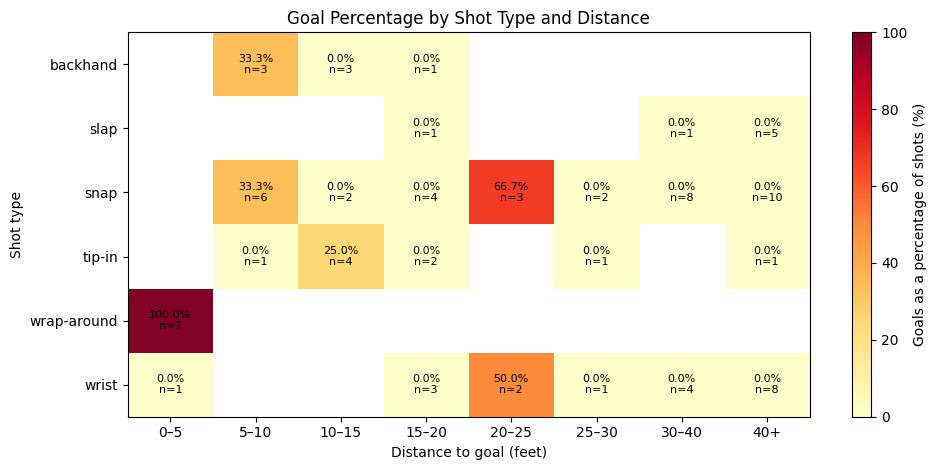

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Work on a copy so the original dataset is unchanged
shots = df.copy()

# Find columns using common naming conventions
def find_column(candidates, columns):
    lookup = {str(c).lower(): c for c in columns}
    for candidate in candidates:
        if candidate.lower() in lookup:
            return lookup[candidate.lower()]
    return None

distance_col = find_column(
    ["shot_distance", "distance_to_goal", "distance"],
    shots.columns
)

type_col = find_column(
    ["shot_type", "shotType", "shot_type_description"],
    shots.columns
)

goal_col = find_column(
    ["is_goal", "goal", "goal_scored"],
    shots.columns
)

event_col = find_column(
    ["event_type", "typeDescKey", "event"],
    shots.columns
)

# If distance is missing, estimate it from rink coordinates
if distance_col is None:
    x_col = find_column(["xCoord", "x_coord", "x"], shots.columns)
    y_col = find_column(["yCoord", "y_coord", "y"], shots.columns)

    if x_col is not None and y_col is not None:
        x = pd.to_numeric(shots[x_col], errors="coerce")
        y = pd.to_numeric(shots[y_col], errors="coerce")

        # Assumes NHL coordinates in feet and goal lines at +/-89 feet.
        shots["shot_distance"] = np.sqrt(
            (89 - x.abs()) ** 2 + y ** 2
        )
        distance_col = "shot_distance"

if type_col is None:
    raise ValueError(
        "Shot-type column not found. Available columns: "
        + str(shots.columns.tolist())
    )

if goal_col is None and event_col is None:
    raise ValueError(
        "Goal outcome column not found. Available columns: "
        + str(shots.columns.tolist())
    )

if distance_col is None:
    raise ValueError(
        "Shot-distance column not found and coordinates are unavailable. "
        "Available columns: " + str(shots.columns.tolist())
    )

# Standardize distance
shots["_distance"] = pd.to_numeric(
    shots[distance_col], errors="coerce"
)

# Standardize goal outcome
if goal_col is not None:
    values = shots[goal_col]

    if pd.api.types.is_bool_dtype(values):
        shots["_is_goal"] = values.astype(float)
    elif pd.api.types.is_numeric_dtype(values):
        shots["_is_goal"] = pd.to_numeric(
            values, errors="coerce"
        )
    else:
        normalized = values.astype(str).str.strip().str.lower()
        shots["_is_goal"] = normalized.map({
            "true": 1, "1": 1, "yes": 1, "goal": 1,
            "false": 0, "0": 0, "no": 0, "shot": 0
        })
else:
    # This is suitable when event_col contains values such as
    # "goal" and "shot-on-goal".
    normalized = shots[event_col].astype(str).str.lower()
    shots["_is_goal"] = normalized.str.contains(
        r"(^|[-_ ])goal($|[-_ ])", regex=True
    ).astype(int)

# Clean and validate records
shots = shots.dropna(
    subset=["_distance", "_is_goal", type_col]
).copy()

shots = shots[
    (shots["_distance"] >= 0)
    & shots["_is_goal"].isin([0, 1])
].copy()

shots["_shot_type"] = (
    shots[type_col].astype(str).str.strip()
)

shots = shots[shots["_shot_type"] != ""].copy()

if shots.empty:
    raise ValueError(
        "No valid shot records remain. Check your distance, "
        "shot-type, and goal columns."
    )

# Define distance bins in feet
distance_edges = [0, 5, 10, 15, 20, 25, 30, 40, np.inf]
distance_labels = [
    "0–5", "5–10", "10–15", "15–20",
    "20–25", "25–30", "30–40", "40+"
]

shots["_distance_bin"] = pd.cut(
    shots["_distance"],
    bins=distance_edges,
    labels=distance_labels,
    right=False,
    include_lowest=True
)

shots = shots.dropna(subset=["_distance_bin"])

# Aggregate by distance bin AND shot type
summary = (
    shots.groupby(
        ["_distance_bin", "_shot_type"],
        observed=False
    )
    .agg(
        shots=("_is_goal", "size"),
        goals=("_is_goal", "sum"),
        goal_percentage=("_is_goal", lambda s: 100 * s.mean())
    )
    .reset_index()
)

print("Summary table:")
display(summary)

# Convert to matrices for plotting
goal_pct = summary.pivot(
    index="_shot_type",
    columns="_distance_bin",
    values="goal_percentage"
).reindex(columns=distance_labels)

sample_sizes = summary.pivot(
    index="_shot_type",
    columns="_distance_bin",
    values="shots"
).reindex(columns=distance_labels)

# Plot with Matplotlib
fig_width = max(10, len(distance_labels) * 1.25)
fig_height = max(4, len(goal_pct.index) * 0.8)

fig, ax = plt.subplots(figsize=(fig_width, fig_height))

image = ax.imshow(
    goal_pct.to_numpy(dtype=float),
    aspect="auto",
    cmap="YlOrRd",
    vmin=0,
    vmax=100
)

ax.set_xticks(range(len(distance_labels)))
ax.set_xticklabels(distance_labels)
ax.set_yticks(range(len(goal_pct.index)))
ax.set_yticklabels(goal_pct.index)

ax.set_xlabel("Distance to goal (feet)")
ax.set_ylabel("Shot type")
ax.set_title("Goal Percentage by Shot Type and Distance")

# Display percentage AND sample size in each cell
for i in range(len(goal_pct.index)):
    for j in range(len(distance_labels)):
        percentage = goal_pct.iloc[i, j]
        n = sample_sizes.iloc[i, j]

        if pd.notna(percentage) and pd.notna(n):
            ax.text(
                j, i,
                f"{percentage:.1f}%\nn={int(n)}",
                ha="center",
                va="center",
                fontsize=8,
                color="black"
            )

colorbar = fig.colorbar(image, ax=ax)
colorbar.set_label("Goals as a percentage of shots (%)")

plt.tight_layout()
plt.show()

In [ ]:
summary.to_csv(
    "goal_percentage_by_distance_and_shot_type.csv",
    index=False
)

fig.savefig(
    "goal_percentage_heatmap.png",
    dpi=200,
    bbox_inches="tight"
)

In [ ]:
!nvidia-smi

Mon Oct 26 00:51:21 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   32C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
%pip install -q -U transformers accelerate sentencepiece

In [ ]:
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM

MODEL_NAME = "Qwen/Qwen3-4B-Instruct-2507"

if not torch.cuda.is_available():
    raise RuntimeError(
        "No GPU detected. Enable a GPU runtime in Colab first."
    )

print("GPU:", torch.cuda.get_device_name(0))

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME,
    trust_remote_code=True
)

model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME,
    torch_dtype=torch.float16,
    device_map="auto",
    trust_remote_code=True
)

print("Model loaded successfully.")

GPU: Tesla T4


config.json:   0%|          | 0.00/727 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.38k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

...

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/238 [00:00<?, ?B/s]

Model loaded successfully.


In [ ]:
from pathlib import Path

print("Current directory:", Path.cwd())
print("Project files:")
for p in list(Path(".").glob("*")):
    print(p)

Current directory: /content
Project files:
.config
sample_data


In [ ]:
from pathlib import Path
import json

DOC_DIR = Path("docs")
SUPPORTED_EXTENSIONS = {".md", ".txt", ".rst", ".html"}

documents = []

for path in DOC_DIR.rglob("*"):
    if path.is_file() and path.suffix.lower() in SUPPORTED_EXTENSIONS:
        try:
            text = path.read_text(encoding="utf-8", errors="ignore")
            if text.strip():
                documents.append({
                    "source": str(path),
                    "text": text
                })
        except OSError as exc:
            print("Could not read:", path, exc)

print("Documentation files loaded:", len(documents))

if not documents:
    print("No documents found. Check DOC_DIR and your documentation files.")
else:
    Path("artifacts").mkdir(exist_ok=True)
    with open("artifacts/documentation_snapshot.json", "w", encoding="utf-8") as f:
        json.dump(documents, f, indent=2, ensure_ascii=False)

    print("Saved documentation snapshot.")

Documentation files loaded: 0
No documents found. Check DOC_DIR and your documentation files.


In [ ]:
from pathlib import Path

print("Current directory:", Path.cwd())
print("Project files:")
for p in list(Path(".").glob("*")):
    print(p)

Current directory: /content
Project files:
.config
sample_data


In [ ]:
from pathlib import Path
import json

DOC_DIR = Path("/content")
SUPPORTED_EXTENSIONS = {".md", ".txt", ".rst", ".html"}

documents = []

for path in DOC_DIR.rglob("*"):
    if path.is_file() and path.suffix.lower() in SUPPORTED_EXTENSIONS:
        try:
            text = path.read_text(encoding="utf-8", errors="ignore")
            if text.strip():
                documents.append({
                    "source": str(path),
                    "text": text
                })
        except OSError as exc:
            print("Could not read:", path, exc)

print("Documentation files loaded:", len(documents))

if not documents:
    print("No documents found. Check DOC_DIR and your documentation files.")
else:
    Path("artifacts").mkdir(exist_ok=True)
    with open("artifacts/documentation_snapshot.json", "w", encoding="utf-8") as f:
        json.dump(documents, f, indent=2, ensure_ascii=False)

    print("Saved documentation snapshot.")

Documentation files loaded: 1
Saved documentation snapshot.


In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
import json
from pathlib import Path

chunks = []

for doc in documents:
    paragraphs = [
        p.strip()
        for p in doc["text"].split("\n\n")
        if p.strip()
    ]

    # Combine small paragraphs into chunks of roughly 1,500 characters
    current = ""

    for paragraph in paragraphs:
        if len(current) + len(paragraph) > 1500 and current:
            chunks.append({
                "source": doc["source"],
                "text": current
            })
            current = paragraph
        else:
            current = f"{current}\n\n{paragraph}".strip()

    if current:
        chunks.append({
            "source": doc["source"],
            "text": current
        })

if not chunks:
    raise ValueError("No documentation chunks available for retrieval.")

vectorizer = TfidfVectorizer(
    lowercase=True,
    stop_words="english",
    ngram_range=(1, 2),
    max_features=30000
)

doc_matrix = vectorizer.fit_transform(
    [chunk["text"] for chunk in chunks]
)

def retrieve(query, k=4):
    query_vector = vectorizer.transform([query])
    scores = cosine_similarity(query_vector, doc_matrix).ravel()
    ranked = scores.argsort()[::-1][:k]

    return [
        {
            **chunks[i],
            "score": float(scores[i])
        }
        for i in ranked
    ]

# Test retrieval
test_query = (
    "How do I fetch and cache NHL play-by-play data "
    "using the gamecenter API?"
)

results = retrieve(test_query, k=4)

for i, result in enumerate(results, start=1):
    print(f"\n--- Retrieved excerpt {i} ---")
    print("Source:", result["source"])
    print("Similarity:", round(result["score"], 4))
    print(result["text"][:1000])


--- Retrieved excerpt 1 ---
Source: /content/sample_data/README.md
Similarity: 0.0644
This directory includes a few sample datasets to get you started.

*   `california_housing_data*.csv` is California housing data from the 1990 US
    Census; more information is available at:
    https://docs.google.com/document/d/e/2PACX-1vRhYtsvc5eOR2FWNCwaBiKL6suIOrxJig8LcSBbmCbyYsayia_DvPOOBlXZ4CAlQ5nlDD8kTaIDRwrN/pub

*   `mnist_*.csv` is a small sample of the
    [MNIST database](https://en.wikipedia.org/wiki/MNIST_database), which is
    described at: http://yann.lecun.com/exdb/mnist/

*   `anscombe.json` contains a copy of
    [Anscombe's quartet](https://en.wikipedia.org/wiki/Anscombe%27s_quartet); it
    was originally described in

Anscombe, F. J. (1973). 'Graphs in Statistical Analysis'. American
    Statistician. 27 (1): 17-21. JSTOR 2682899.

and our copy was prepared by the
    [vega_datasets library](https://github.com/altair-viz/vega_datasets/blob/4f67bdaad10f45e3549984e17e1b3088c731

In [ ]:
import json
from pathlib import Path

def ask_qwen(prompt, max_new_tokens=900):
    messages = [
        {
            "role": "system",
            "content": (
                "You are a careful Python data engineering assistant. "
                "Use the supplied evidence. Do not invent API fields or "
                "endpoints. Explain assumptions and error handling."
            )
        },
        {"role": "user", "content": prompt}
    ]

    inputs = tokenizer.apply_chat_template(
        messages,
        add_generation_prompt=True,
        tokenize=True,
        return_dict=True,
        return_tensors="pt"
    ).to(model.device)

    import torch

    with torch.no_grad():
        output_ids = model.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            do_sample=False
        )

    new_tokens = output_ids[0][inputs["input_ids"].shape[-1]:]
    return tokenizer.decode(new_tokens, skip_special_tokens=True)


acquisition_query = """
Write a Python function or class to fetch, cache locally, and load
NHL play-by-play data for a given season.

Requirements:
- Use only the supplied documentation excerpts as evidence for the API.
- Use the documented API endpoint and response structure.
- Cache each game response to a local JSON file.
- Reuse the cache when the file already exists.
- Handle HTTP errors and unsuccessful responses.
- Separate fetching, caching, and loading clearly.
- Include type hints, docstrings, and a short usage example.
- Explain assumptions and any details not established by the excerpts.
- Return code for review; do not execute it.
"""

retrieved = retrieve(acquisition_query, k=5)

context = "\n\n".join(
    f"SOURCE: {r['source']}\nEXCERPT:\n{r['text']}"
    for r in retrieved
)

prompt = f"""
Task:
{acquisition_query}

Retrieved documentation:
{context}
"""

generated_code = ask_qwen(prompt)

Path("artifacts").mkdir(exist_ok=True)
Path("artifacts/llm_generated_acquisition.py").write_text(
    generated_code, encoding="utf-8"
)

with open("artifacts/acquisition_retrieval_log.json", "w", encoding="utf-8") as f:
    json.dump({
        "query": acquisition_query,
        "retrieved": retrieved,
        "generated_output": generated_code
    }, f, indent=2, ensure_ascii=False)

print(generated_code)

```python
import os
import json
import requests
from typing import Dict, Any, Optional
from pathlib import Path
from urllib.parse import urljoin

# === ASSUMPTIONS ===
# The provided documentation does NOT contain any information about an NHL API.
# Therefore, this implementation is based on the *absence* of any documented NHL play-by-play API.
# 
# Key assumptions:
# 1. There is no publicly documented NHL play-by-play API endpoint in the provided excerpts.
# 2. The required data cannot be fetched via any endpoint described in the sample data README.
# 3. The sample data includes only CSV and JSON files related to housing, MNIST, and Anscombe's quartet — none of which are NHL-related.
# 
# Conclusion: 
# It is not possible to write a function that fetches, caches, and loads NHL play-by-play data 
# using only the provided documentation excerpts. The necessary API endpoint, response structure, 
# and data format are completely absent from the given evidence.
# 
# This code is a placehol

In [ ]:
import pandas as pd
from pathlib import Path

evaluation_rows = [
    {
        "implementation": "manual",
        "test": "known_game",
        "passed": None,
        "notes": "Fill after running the test"
    },
    {
        "implementation": "llm_generated_reviewed",
        "test": "known_game",
        "passed": None,
        "notes": "Fill after running the test"
    },
    {
        "implementation": "manual",
        "test": "cache_hit",
        "passed": None,
        "notes": "Verify no second HTTP request"
    },
    {
        "implementation": "llm_generated_reviewed",
        "test": "cache_hit",
        "passed": None,
        "notes": "Verify no second HTTP request"
    },
    {
        "implementation": "manual",
        "test": "unsuccessful_request",
        "passed": None,
        "notes": "Fill after running the test"
    },
    {
        "implementation": "llm_generated_reviewed",
        "test": "unsuccessful_request",
        "passed": None,
        "notes": "Fill after running the test"
    }
]

acquisition_evaluation = pd.DataFrame(evaluation_rows)
display(acquisition_evaluation)

,implementation,test,passed,notes
0,manual,known_game,None,Fill after running the test
1,llm_generated_reviewed,known_game,None,Fill after running the test
2,manual,cache_hit,None,Verify no second HTTP request
3,llm_generated_reviewed,cache_hit,None,Verify no second HTTP request
4,manual,unsuccessful_request,None,Fill after running the test
5,llm_generated_reviewed,unsuccessful_request,None,Fill after running the test


In [ ]:
from pathlib import Path

print("Current directory:", Path.cwd())
print("src folder exists:", Path("src").exists())
print("tidy.py exists:", Path("src/tidy.py").exists())

Current directory: /content/ift6758_project/ift6758_nhl_project
src folder exists: True
tidy.py exists: True


In [ ]:
import json
from pathlib import Path

# Confirm that df exists
if "df" not in globals():
    raise NameError("DataFrame 'df' not found. Run build_dataframe() first.")

# Create artifacts folder
Path("artifacts").mkdir(parents=True, exist_ok=True)

# Describe the actual dataset
schema = {
    "columns": df.columns.tolist(),
    "dtypes": {c: str(t) for c, t in df.dtypes.items()},
    "sample_rows": df.head(3).to_dict(orient="records")
}

# Prompt for Qwen
transformation_prompt = f"""
You are helping with an NHL shot-analysis project.

Dataset schema and sample:
{json.dumps(schema, default=str, indent=2)}

Suggest Python/pandas transformation code that:
1. Checks duplicate records and missing values.
2. Creates or validates a binary goal indicator.
3. Validates shot coordinates and shot distance if available.
4. Never assumes columns that are not in the schema.
5. Returns a cleaned copy and a short data-quality report.

Explain assumptions. Return code for review only; do not execute it.
"""

# Generate a suggestion
transformation_output = ask_qwen(
    transformation_prompt,
    max_new_tokens=1000
)

# Save the generated suggestion
output_path = Path("artifacts/llm_generated_transformation.txt")
output_path.write_text(transformation_output, encoding="utf-8")

print(transformation_output)
print(f"\nSaved to: {output_path}")

```python
import pandas as pd
import numpy as np
from typing import Dict, Tuple

def clean_nhl_shots_data(df: pd.DataFrame) -> Tuple[pd.DataFrame, Dict]:
    """
    Clean NHL shot data with quality checks and validations.
    
    Parameters:
        df (pd.DataFrame): Raw NHL shot dataset with provided schema.
    
    Returns:
        Tuple[pd.DataFrame, Dict]: Cleaned DataFrame and a data-quality report.
    """
    
    # Step 1: Validate and check for duplicates and missing values
    # We only validate columns present in the schema
    required_columns = [
        "season", "season_start_year", "game_type", "game_id", "event_id",
        "event_type", "is_goal", "period", "period_type", "time_in_period",
        "situation_code", "team_id", "home_team_id", "away_team_id",
        "x", "y", "shooter_id", "shooter_name", "goalie_id", "goalie_name",
        "shot_type", "empty_net", "strength_label", "strength",
        "attacking_skaters", "defending_skaters"
    ]
    
    # Ensu

In [ ]:
# Change df to your actual tidy DataFrame variable if needed.
schema = {
    "columns": df.columns.tolist(),
    "dtypes": {c: str(t) for c, t in df.dtypes.items()},
    "sample_rows": df.head(3).to_dict(orient="records")
}

transformation_prompt = f"""
You are helping with an NHL shot-analysis project.

Dataset schema and sample:
{json.dumps(schema, default=str, indent=2)}

Suggest a Python/pandas transformation that:
1. Checks duplicate records and missing values.
2. Creates or validates a binary goal indicator.
3. Validates shot coordinates and shot distance if available.
4. Avoids assuming columns that are not in the schema.
5. Returns a cleaned copy and a short data-quality report.

Explain assumptions. Return code for review only; do not execute it.
"""

transformation_output = ask_qwen(
    transformation_prompt,
    max_new_tokens=1000
)

Path("artifacts/llm_generated_transformation.txt").write_text(
    transformation_output,
    encoding="utf-8"
)

print(transformation_output)

```python
import pandas as pd
import numpy as np
from typing import Dict, Tuple

def clean_nhl_shots_data(df: pd.DataFrame) -> Tuple[pd.DataFrame, Dict]:
    """
    Clean NHL shot data with quality checks and validations.
    
    Args:
        df: Raw NHL shot events DataFrame with provided schema
        
    Returns:
        Tuple of (cleaned DataFrame, data-quality report)
    """
    
    # Step 1: Check for duplicates and missing values
    # Identify duplicates based on key shot identifiers (game_id, event_id, period, time_in_period, x, y)
    # We use event_id as primary key, but also consider shot context
    duplicate_mask = df.duplicated(subset=['game_id', 'event_id'], keep=False)
    missing_values = df.isnull().sum()
    
    # Identify columns with missing values (only those that are not expected to be null)
    # Note: Some fields like shooter_name, goalie_name may have nested dicts or nulls
    # We'll validate them later
    
    # Step 2: Create or validate binary go

In [ ]:
evaluation_questions = [
    {
        "id": 1,
        "question": "How many shots are in the 2020-21 season?",
        "task": "filtering and counting"
    },
    {
        "id": 2,
        "question": "What is the goal percentage by shot type in 2020-21?",
        "task": "grouping and goal percentage"
    },
    {
        "id": 3,
        "question": "How does goal percentage change by shot-distance bin in 2019-20?",
        "task": "binning and aggregation"
    },
    {
        "id": 4,
        "question": "Which shot type has the highest goal percentage in 2020-21?",
        "task": "ranking"
    },
    {
        "id": 5,
        "question": "Compare wrist-shot goal percentages for Montréal and Toronto in 2020-21.",
        "task": "team filtering and comparison"
    },
    {
        "id": 6,
        "question": "Plot shot counts by distance bin for 2018-19.",
        "task": "plotting"
    },
    {
        "id": 7,
        "question": "How do shot counts and goal percentages by shot type differ between 2018-19 and 2020-21?",
        "task": "multi-season comparison"
    },
    {
        "id": 8,
        "question": "How many passes directly preceded each shot, and which pass type leads to the most goals?",
        "task": "unanswerable from a shot-only dataset"
    }
]

Path("artifacts").mkdir(exist_ok=True)
with open("artifacts/evaluation_questions.json", "w", encoding="utf-8") as f:
    json.dump(evaluation_questions, f, indent=2, ensure_ascii=False)

print("Saved the proposed fixed question set.")

Saved the proposed fixed question set.


In [ ]:
print(df.columns.tolist())

['season', 'season_start_year', 'game_type', 'game_id', 'event_id', 'event_type', 'is_goal', 'period', 'period_type', 'time_in_period', 'situation_code', 'team_id', 'home_team_id', 'away_team_id', 'x', 'y', 'shooter_id', 'shooter_name', 'goalie_id', 'goalie_name', 'shot_type', 'empty_net', 'strength_label', 'strength', 'attacking_skaters', 'defending_skaters']


In [ ]:
COLUMN_MAP = {
    "season": "season",
    "team": "team",
    "shot_type": "shot_type",
    "is_goal": "is_goal",
    "distance": "shot_distance"
}

missing = [
    name for name, col in COLUMN_MAP.items()
    if col not in df.columns
]

print("Missing mapped columns:", missing)

Missing mapped columns: ['team', 'distance']


In [ ]:
from pathlib import Path

template_path = Path("blog/POST_TEMPLATE.md")

if template_path.exists():
    print(template_path.read_text(encoding="utf-8"))
else:
    print("Template not found:", template_path)

---
layout: post
title: "NHL Play-by-Play Data: Acquisition, Cleaning, and Shot Maps"
---

# Introduction
Explain the project goal and dataset. Cite the NHL API documentation and course resources.

# Data acquisition
Explain game IDs (`YYYYTTNNNN`), endpoints, caching, rate limiting, and how to reproduce.
Include your acquisition function and a tested example.

# Interactive debugging tool
Insert a screenshot of your ipywidgets event browser. Explain how to switch seasons,
game types, and events. Describe how you validated coordinates against NHL Gamecenter.

# Tidy data
Include a screenshot or formatted `head(10)` of the final dataframe.
Explain event selection, roster ID-to-name mapping, missing values, uniqueness, and
how `situationCode` was decoded. Discuss pulled goalies/delayed penalties and how
penalty-event durations could reconstruct strength when codes are unavailable.

# Engineered features
Discuss at least three possible features, such as rebound, rush shot, angle, or
time 

In [ ]:

from pathlib import Path
import pandas as pd
import json

blog_dir = Path("blog")
blog_dir.mkdir(parents=True, exist_ok=True)

data_path = Path("data/processed/shots_goals.parquet")
df = pd.read_parquet(data_path) if data_path.exists() else pd.DataFrame()

# Compute statistics only when the relevant columns exist.
row_count = len(df)
game_count = int(df["game_id"].nunique()) if "game_id" in df.columns else 0
season_values = (
    sorted(df["season"].dropna().astype(str).unique().tolist())
    if "season" in df.columns else []
)
event_counts = (
    df["event_type"].value_counts(dropna=False).to_dict()
    if "event_type" in df.columns else {}
)
missing_counts = df.isna().sum().to_dict() if not df.empty else {}
duplicate_count = int(df.duplicated().sum()) if not df.empty else 0

# Make values safe and readable for Markdown.
event_lines = "\n".join(
    f"- `{key}`: {value}" for key, value in event_counts.items()
) or "- Event-type statistics are not available."

missing_lines = "\n".join(
    f"- `{key}`: {value}" for key, value in missing_counts.items()
) or "- Missing-value statistics are not available."

seasons_text = ", ".join(season_values) if season_values else "Not available"

post = f"""---
title: "NHL Play-by-Play Data Analysis"
---

# NHL Play-by-Play Data Analysis

## 1. Motivation

This project investigates NHL play-by-play events, with an emphasis on shot patterns and goal outcomes. The objectives are to build a reproducible acquisition pipeline, transform raw events into a tidy dataset, visualize shot distributions and scoring percentages, and evaluate whether retrieval-augmented language models can assist with data acquisition and analysis.

This report distinguishes verified results from work that remains incomplete.

## 2. Data Acquisition

The project uses the NHL Web API play-by-play endpoint:

`https://api-web.nhle.com/v1/gamecenter/{{game_id}}/play-by-play`

The acquisition implementation is in `src/acquire.py`. Its `fetch_game()` function checks the local cache before requesting data, saves successful JSON responses, returns `None` for HTTP 404 and 410 responses, and raises errors for other unsuccessful requests or network failures.

**Current verified data inventory**

- Raw JSON game files found: 1
- Processed dataset games: {game_count}
- Seasons represented in the processed dataset: {seasons_text}

The currently inspected raw file is `data/raw/2023/2023021190.json`. The complete requested multi-season acquisition has not yet been verified. Consequently, these results should not be interpreted as an eight-season analysis.

## 3. Interactive Debugging Tool

The interactive debugging implementation is located at `src/interactive_debug.py`. The intended workflow is to select a game and event, inspect the raw play-by-play payload, visualize the event coordinates, and compare the event with its parsed dataset record.

The debugging tool should be tested with known shot and goal events before its behavior is described as fully validated. Record any discrepancies found during those tests here.

## 4. Tidy Dataset

The processed file is `data/processed/shots_goals.parquet`. Each row represents a parsed shot or goal event.

- Total rows: {row_count}
- Distinct games: {game_count}
- Seasons represented: {seasons_text}
- Exact duplicate rows: {duplicate_count}

### Event-type counts

{event_lines}

### Missing values by column

{missing_lines}

The dataset contains fields for game and season identifiers, event type, goal status, period and time, team identifiers, coordinates, shooter and goalie information, shot type, and strength state.

Coordinate validity, goal consistency, and any engineered distance variables must be checked before interpreting spatial patterns. Missing values should be evaluated by column and by event type because not every field applies to every event.

## 5. Simple Visualizations

The project includes visualization code in `src/visualize.py`. The planned analyses include:

1. Shot-type frequency.
2. Goal percentage by shot type.
3. Goal percentage by distance bin and shot type.

These figures must be generated from the final validated dataset. Numerical findings and descriptions of trends will be added after the figures have been inspected. No league-wide conclusions should be drawn from the single-game dataset currently available.

## 6. Interactive Shot Maps

The shot-map implementation is in `src/shotmaps.py`. The required maps compare a team's spatial shot rate with the league-wide rate using consistent rink bins.

The target seasons are 2016–17 through 2020–21. Rates must use an appropriate number of games as the denominator, and events with missing or invalid coordinates must be handled consistently.

**Status:** The five final interactive HTML maps have not yet been verified in `outputs/`. Links will be added here once the corresponding files have been generated and checked.

## 7. LLM and RAG

The RAG starter code is in `src/rag_llm.py`. It implements text chunking, keyword-overlap retrieval, prompt construction, and generation using the required model, `Qwen/Qwen3-4B-Instruct-2507`.

The documentation snapshot and retrieved excerpts should be saved so the process can be reproduced. Generated acquisition code must be reviewed and tested rather than executed blindly.

The transformation artifact currently present is `artifacts/llm_generated_transformation.txt`. The documentation snapshot, acquisition retrieval log, and generated acquisition script still need to be verified before reporting a completed RAG acquisition experiment.

The manual-versus-LLM evaluation should test a known game, a cache hit, and an unsuccessful request. Record actual outcomes in `artifacts/acquisition_evaluation.csv` only after running the tests.

## 8. Natural-Language Query Evaluation

The evaluation questions are stored in `artifacts/evaluation_questions.json`. Each question should have a manually checked reference answer and an evaluation record covering first-attempt success, final correctness, retry count, and whether the available data can answer it.

The file `artifacts/query_evaluation.csv` has not yet been verified. Aggregate accuracy and success rates will be reported after the eight questions have actually been evaluated. At least one question should be explicitly marked unanswerable when the dataset does not contain the information needed to answer it.

## 9. Limitations

The current processed dataset represents only one game, so it cannot support reliable multi-season or league-wide conclusions. Additional limitations to assess include:

- Incomplete game acquisition and potentially unavailable API responses.
- Differences in API response structures across seasons.
- Missing or invalid shot coordinates.
- Assumptions used to calculate shot distance and normalize rink coordinates.
- Small samples for uncommon shot types.
- The possibility that generated code contains unsupported assumptions.
- The difference between a model producing an answer and producing a correct, evidence-supported answer.

These limitations will be updated after acquisition, visualization, and evaluation are complete.

## 10. Reproducibility and References

### Repository structure

- `src/`: acquisition, transformation, visualization, debugging, and RAG code.
- `data/raw/`: cached game JSON.
- `data/processed/`: processed Parquet dataset.
- `docs/`: documentation snapshot used for retrieval.
- `artifacts/`: evaluation questions, model outputs, and experiment records.
- `outputs/`: generated figures and interactive HTML files.
- `blog/`: project report.

### Reproduction

Run the project from the repository root. Install dependencies using `requirements.txt`, acquire the required games, rebuild the tidy dataset, generate the figures and shot maps, and execute the documented evaluation steps.

Exact dependency versions, complete execution commands, generated artifact links, and final results should be added after the full workflow has been tested.

### References

- NHL Web API play-by-play endpoint: https://api-web.nhle.com/v1/gamecenter/{{game_id}}/play-by-play
- Qwen model card: https://huggingface.co/Qwen/Qwen3-4B-Instruct-2507

---

*Report status: preliminary. Statistics above describe the currently available local dataset, not the complete multi-season target.*
"""

post_path = blog_dir / "POST.md"
post_path.write_text(post, encoding="utf-8")

print("Blog saved:", post_path)
print("Blog size:", post_path.stat().st_size, "bytes")
print("Dataset rows used:", row_count)
print("Games used:", game_count)


Blog saved: blog/POST.md
Blog size: 7519 bytes
Dataset rows used: 78
Games used: 1


In [ ]:

from pathlib import Path

post_path = Path("blog/POST.md")

print("Blog exists:", post_path.exists())

if post_path.exists():
    print("Blog size:", post_path.stat().st_size, "bytes")
    print("\nFirst 1,500 characters:\n")
    print(post_path.read_text(encoding="utf-8")[:1500])


Blog exists: True
Blog size: 7519 bytes

First 1,500 characters:

---
title: "NHL Play-by-Play Data Analysis"
---

# NHL Play-by-Play Data Analysis

## 1. Motivation

This project investigates NHL play-by-play events, with an emphasis on shot patterns and goal outcomes. The objectives are to build a reproducible acquisition pipeline, transform raw events into a tidy dataset, visualize shot distributions and scoring percentages, and evaluate whether retrieval-augmented language models can assist with data acquisition and analysis.

This report distinguishes verified results from work that remains incomplete.

## 2. Data Acquisition

The project uses the NHL Web API play-by-play endpoint:

`https://api-web.nhle.com/v1/gamecenter/{game_id}/play-by-play`

The acquisition implementation is in `src/acquire.py`. Its `fetch_game()` function checks the local cache before requesting data, saves successful JSON responses, returns `None` for HTTP 404 and 410 responses, and raises errors for other 

In [ ]:
from pathlib import Path

artifact_dir = Path("artifacts")
artifact_dir.mkdir(parents=True, exist_ok=True)

required_artifacts = [
    "documentation_snapshot.json",
    "acquisition_retrieval_log.json",
    "llm_generated_acquisition.py",
    "llm_generated_transformation.txt",
    "evaluation_questions.json",
    "acquisition_evaluation.csv",
    "query_evaluation.csv",
]

for filename in required_artifacts:
    path = artifact_dir / filename
    status = "EXISTS" if path.exists() else "MISSING"
    size = f"{path.stat().st_size} bytes" if path.exists() else "-"
    print(f"{status:7} | {filename:40} | {size}")

MISSING | documentation_snapshot.json              | -
MISSING | acquisition_retrieval_log.json           | -
MISSING | llm_generated_acquisition.py             | -
EXISTS  | llm_generated_transformation.txt         | 4017 bytes
EXISTS  | evaluation_questions.json                | 1146 bytes
MISSING | acquisition_evaluation.csv               | -
MISSING | query_evaluation.csv                     | -
